# Object-based (segment) classification

*Section 4 — Image classification, notebook 4 of 5.* Previous: `03_supervised_pixel_classification`. Next: `05_mangrove_classification_interpretation`.

**You will learn:**
- how to segment an image into groups of similar neighbouring pixels (segments, also called clumps or objects) with the Shepherd segmentation algorithm;
- how to calculate per-segment features (zonal statistics of the segments) and store them with the segment polygons;
- how to extract segment training samples, why there are far fewer of them than pixel samples, and how to combine them with pixel samples using `combine_cls_samples`;
- how to train a classifier, apply it to the segments, turn the result into a classified image and compare it with the pixel classification using `create_map_panels`.

**Before you start:** notebook `03_supervised_pixel_classification` (the `ClassificationConfig`, sample tables and training a classifier). If you have run it, its classification is compared with this one at the end.

**Data:** `../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif` (Sentinel-2, 20 m) and the training polygons `../data/cls_data/aber_sen2_cls_training.gpkg` (one layer per class).

**Run time:** about 1 minute.

## Introduction

This notebook will go through the steps to undertake a classification of image segments rather than of individual pixels.

A number of studies have proposed that segmenting an image and classifying the segments can produce a better classification result than classifying individual pixels.

The notebook will go through the following steps:

 * Perform segmentation
 * Populate segments with data (per-segment features)
 * Extract sample data
 * Split sample data into training, testing and validation sets
 * Train classifier
 * Apply classifier

> **RSGISLib users:** RSGISLib stored the segment statistics and classification in a raster attribute table (RAT) in a KEA file (`rastergis.populate_rat_with_stats`, `classratutils`, `apply_sklearn_classifier_rat`, `collapse_classes`). rsgispy has no RATs: the segments are a label raster (GeoTIFF) and the per-segment features are stored in a vector layer of the segment polygons (GeoParquet), with one row per segment. The classification is added to that layer and then rasterised back onto the segments.

## Running the notebook

The notebook has been run and saved with its outputs, so you can see what the outputs should look like and browse it online without running it.

If you run the notebook yourself, it is a good idea to clear the stored outputs first: in JupyterLab use *Edit > Clear Outputs of All Cells*, or in the classic Notebook *Cell > All Output > Clear*.

# 1. Import the modules needed

In [1]:
# Import modules from python standard library
import os

# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline
import matplotlib.pyplot as plt

# Import the geopandas and pandas modules
import geopandas
import pandas

# Import the rsgispy modules for the notebook
import rsgispy
import rsgispy.classification.classsegments as cseg
import rsgispy.classification.classsklearn as csk
import rsgispy.mapping.layout as map_layout
from rsgispy.classification.classdata import (
    ClassificationConfig,
    ClassInfoObj,
    ImageBandInfo,
    combine_cls_samples,
    extract_class_training_samples,
    split_class_samples,
)
from rsgispy.imageutils.metadata import get_band_names
from rsgispy.mapping.raster import create_thematic_raster_map
from rsgispy.segmentation.shepherd import shepherd_segmentation
from rsgispy.vector.create import polygonise_raster_to_vec_lyr

# scikit-learn imports
from sklearn.ensemble import RandomForestClassifier

# 2. Define the input image

The code below defines the path to the input image, and also which bands will be used for the classification:

In [2]:
# Input Sentinel-2 image file with 20 m resolution pixels.
input_img = "../data/sen2_20180629_t30uvd_orb037_osgb_stdsref_20m.tif"

img_band_info = list()
img_band_info.append(
    ImageBandInfo(
        input_img,
        name="sen2",
        bands=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
        band_names=get_band_names(input_img),
    )
)

# All the outputs of this notebook are written to this directory.
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

# 3. Perform segmentation

The segmentation groups neighbouring pixels which are (hopefully) of the same class together, in an unsupervised process, to simplify and improve the following classification steps. These kinds of segments (also referred to as clumps or objects) are sometimes called 'super-pixels' (i.e., larger groupings of image pixels with similar properties).

One advantage of having a group of pixels is that it allows statistical properties of the group (e.g., standard deviation) and its shape (e.g., area, compactness) to be calculated alongside a simple mean, which can be useful when trying to classify classes which have a characteristic texture or shape, for example.

However, you should also bear in mind that the boundaries drawn by the segmentation will then be the boundaries within the final map, so any errors within the segmentation will be brought through into the classification result.

The Shepherd segmentation algorithm ([Shepherd et al., 2019](https://doi.org/10.3390/rs11060658)) works in steps:

1. the bands are standardised and the pixels are clustered with K-means (as in notebook 2), using a sample of the pixels;
2. each pixel is given its cluster, and connected pixels of the same cluster become segments;
3. segments smaller than the minimum size are iteratively merged with their spectrally closest neighbour.

In [3]:
segs_img = os.path.join(out_dir, "sen2_20180629_aber_segs.tif")

shepherd_segmentation(
    input_img,
    segs_img,
    n_clusters=60,  # The number of clusters (k) for the initial K-means clustering
    min_pixels=50,  # Minimum number of pixels within a segment
    bands=[8, 9, 3],  # Just use bands 8 (NIR), 9 (SWIR) and 3 (Red)
    sampling=100,  # Speed up the K-means clustering by only using every 100th pixel.
    no_data_val=0,  # Pixels with a value of 0 are not segmented (output 0)
    rnd_seed=42,
    use_pbar=False,  # no progress bar (set to True to see progress)
)

> **RSGISLib users:** `run_shepherd_segmentation` is now `shepherd_segmentation`. It needs no temporary directory, the input bands are always standardised, and `dist_thres` (here left at its default of no limit) is a distance in standardised units.

The output is a label image, where each segment has its own integer ID (from 1; 0 is no data):

In [4]:
import rasterio

with rasterio.open(segs_img) as ds:
    print(f"Number of segments: {ds.read(1).max()}")

Number of segments: 68701


# 4. Create vector polygons for the segments

While the raster segments provide an efficient way of storing and processing the segments, a vector version is helpful for visualising them in a GIS. The command below shows how to vectorise the segments to a vector layer. You will probably find it useful to open the layer produced, alongside the input image, in QGIS to visualise the segmentation.

While raster segments are efficient when dealing with raster data of the same spatial resolution as the segment pixels, when dealing with data at very different resolutions (e.g., segments from Landsat intersecting with MODIS pixels) it can also be useful to use a vector layer and zonal statistics for further data analysis, where the raster datasets do not have to be resampled to the same resolution as the segments. (The features calculated in section 6 are also written to a vector layer of the segment polygons.)

In [5]:
segs_vec_file = os.path.join(out_dir, "sen2_20180629_aber_segs.gpkg")
segs_vec_lyr = "sen2_20180629_aber_segs"

polygonise_raster_to_vec_lyr(
    segs_img,  # The input segmentation image
    segs_vec_file,  # The output vector file name and path
    segs_vec_lyr,  # The output vector layer name
    img_band=1,  # The band within the input image
    mask_img=segs_img,  # A mask image (usually the same as the input image)
    mask_band=1,  # The band within the mask image
    out_format="GPKG",  # The output vector format
)

# 5. Visualise segmentation

It is recommended that you open the segmentation result and/or the vector layer in QGIS to see whether the resulting segments identify the features (i.e., groups of pixels) within the scene which represent the classes you are interested in. For example, if the segmentation has merged pixels of two or more classes which you want to classify, this will result in misclassification within the output.

Below, the image and the segment boundaries drawn over it are shown side by side with `create_map_panels`: the second panel is a `'vector'` panel of the segment boundaries (lines), drawn over the image (`base_img`).

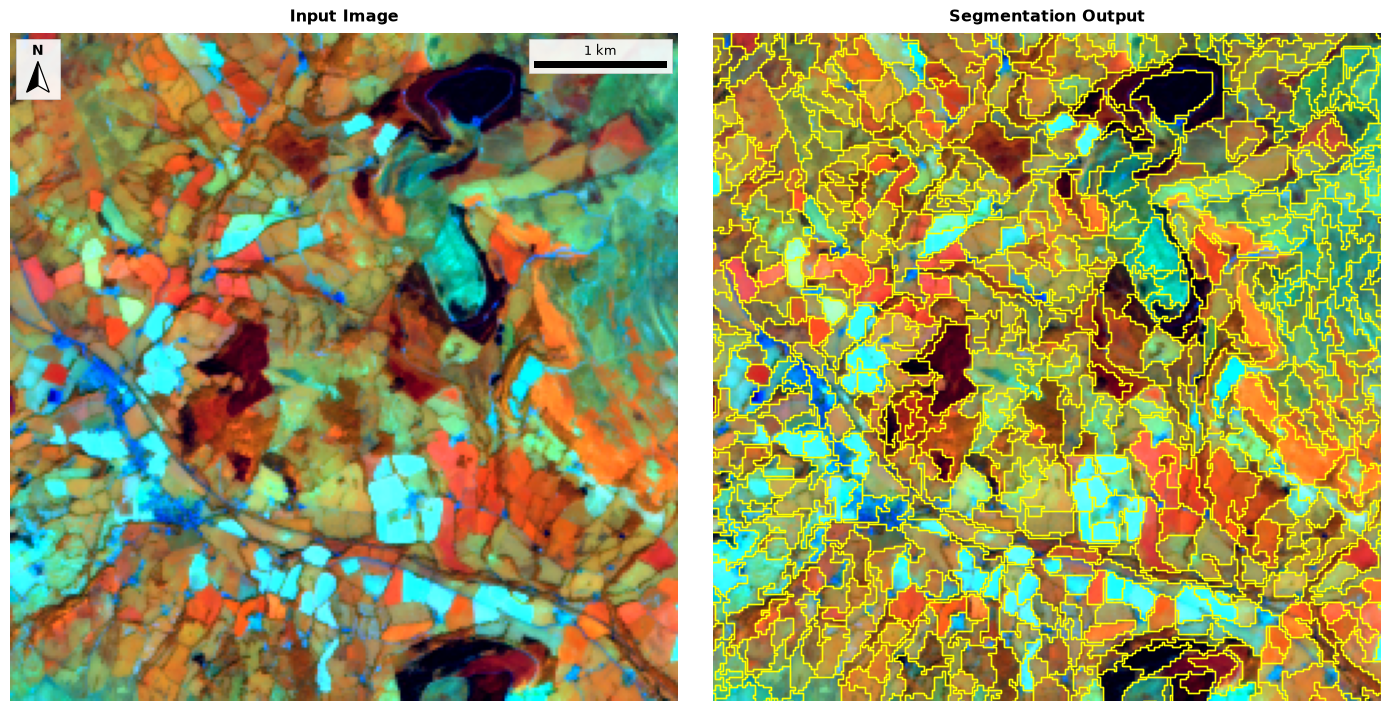

In [6]:
# Define a bbox (xmin, xmax, ymin, ymax) for the subset to be displayed
sub_img_bbox = [295000, 300000, 295000, 300000]
# Subset bbox reformatted for geopandas (xmin, ymin, xmax, ymax)
gp_img_bbox = (sub_img_bbox[0], sub_img_bbox[2], sub_img_bbox[1], sub_img_bbox[3])

# Use geopandas to read the vector layer, just for the bbox
segs_gdf = geopandas.read_file(segs_vec_file, layer=segs_vec_lyr, bbox=gp_img_bbox)
# Just the polygon outlines (as lines).
segs_bounds_gdf = geopandas.GeoDataFrame(geometry=segs_gdf.boundary, crs=segs_gdf.crs)

fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[8, 9, 3], img_stch=rsgispy.IMG_STRETCH_STDEV,
            title="Input Image",
        ),
        map_layout.MapPanel(
            "vector",
            vec=segs_bounds_gdf,
            base_img=input_img,
            base_bands=[8, 9, 3],
            base_stch=rsgispy.IMG_STRETCH_STDEV,
            map_kw={"vec_line_clrs": "yellow", "vec_line_widths": 1.0},
            title="Segmentation Output",
        ),
    ],
    bbox=sub_img_bbox,
    figsize=(14, 7),
)

# 6. Populate segments with features

## 6.1 Define the classes and classification configuration

As in the pixel classification (notebook 3), the classes and their training polygons are defined with `ClassInfoObj` objects and put together with the image bands in a `ClassificationConfig`:

In [7]:
vec_train_file = "../data/cls_data/aber_sen2_cls_training.gpkg"

# class name: (output pixel value, vector layer, (red, green, blue))
classes = {
    "Artificial_Surfaces": (1, "Artificial_Surfaces", (180, 180, 180)),
    "Bare_Rock_Sand": (2, "Bare_Rock_Sand", (131, 250, 252)),
    "Conifer_Forest": (3, "Conifer_Forest", (0, 105, 16)),
    "Deciduous_Forest": (4, "Deciduous_Forest", (62, 168, 78)),
    "Grass_Long": (5, "Grass_Long", (247, 176, 32)),
    "Grass_Short": (6, "Grass_Short", (252, 231, 109)),
    "NonPhoto_Veg": (7, "NonPhotosynthetic_Vegetation", (156, 255, 215)),
    "Scrub": (8, "Scrub", (225, 114, 247)),
    "Water": (9, "Water_Training", (0, 0, 255)),
    "Bracken": (10, "Bracken", (140, 255, 0)),
}

class_info = dict()
for cls_name, (cls_id, lyr_name, clr) in classes.items():
    class_info[cls_name] = ClassInfoObj(
        out_id=cls_id, vec_file=vec_train_file, vec_lyr=lyr_name, colour=clr
    )

cls_cfg = ClassificationConfig(img_band_info, class_info)

## 6.2 Calculate the Sentinel-2 reflectance features

In this case we populate the segments with just the mean reflectance values of the Sentinel-2 bands within each segment. `create_cls_segment_features` calculates the statistics (zonal statistics of each segment, with `rsgispy.zonalstats.labels`), polygonises the segments and writes the polygons with the features to a GeoParquet file. It returns the classification config with the segment information added (`seg_info`), which is also saved to a JSON file for the following steps.

Other statistics (e.g., `"stddev"`, `"min"`, `"max"`, percentiles) and shape metrics (e.g., `"area"`, `"compactness"`) can also be calculated; see the exercise at the end.

In [8]:
segs_feats_file = os.path.join(out_dir, "sen2_20180629_aber_segs_feats.parquet")
cls_seg_cfg_file = os.path.join(out_dir, "cls_seg_config.json")

cls_cfg = cseg.create_cls_segment_features(
    cls_cfg,
    segs_img,
    segs_feats_file,
    out_cfg_file=cls_seg_cfg_file,
    stats=["mean"],  # per-band statistics
    shape_metrics=[],  # no shape metrics
    band_opts={"sen2": {"no_data_val": 0}},  # the Sentinel-2 no data value
    overwrite=True,
    use_pbar=False,
)
print(cls_cfg.seg_info.feature_cols)

['Blue_mean', 'Green_mean', 'Red_mean', 'RE_B5_mean', 'RE_B6_mean', 'RE_B7_mean', 'NIR_B8_mean', 'NIR_B8A_mean', 'SWIR1_mean', 'SWIR2_mean']


You can open the GeoParquet file in QGIS and look at the values for each segment, or look at the first few rows with GeoPandas:

In [9]:
segs_feats_gdf = geopandas.read_parquet(segs_feats_file)
segs_feats_gdf.head()

,seg_id,pxl_count,valid,Blue_mean,Green_mean,Red_mean,RE_B5_mean,RE_B6_mean,RE_B7_mean,NIR_B8_mean,NIR_B8A_mean,SWIR1_mean,SWIR2_mean,geometry
0,1,554948,1,31.604932,21.157599,3.808642,3.949961,4.228342,3.859846,2.987662,2.480263,1.167463,1.404106,"POLYGON ((249177.332 326342.255, 249177.332 30..."
1,2,11603,1,44.221236,46.747651,13.636042,11.131862,12.153064,12.696716,11.791950,11.116522,5.008532,4.580540,"POLYGON ((254777.332 326342.255, 254777.332 32..."
2,3,2519,1,55.826518,67.300913,37.177451,29.520445,16.684002,17.553394,16.095673,15.225486,8.393013,6.849940,"POLYGON ((254957.332 326342.255, 254957.332 32..."
3,4,180,1,79.405556,100.644444,112.150000,126.322222,134.972222,136.961111,135.505556,133.161111,100.294444,72.816667,"POLYGON ((254977.332 326342.255, 254977.332 32..."
4,5,93,1,117.139785,147.225806,170.817204,187.935484,204.354839,206.397849,203.483871,208.290323,226.956989,199.430108,"POLYGON ((255077.332 326342.255, 255077.332 32..."


# 7. Extract sample data

## 7.1 Extract segment sample data

The training polygons are now assigned to the segments: a segment is a sample of a class if it is mostly covered by a training polygon of that class (segments covered by polygons of more than one class are dropped). Each segment gives one sample, with its features, however many training polygons fall in it.

In [10]:
seg_smpls_file = os.path.join(out_dir, "seg_smpls.parquet")
seg_smpls_df = cseg.extract_class_segment_samples(cls_seg_cfg_file, out_file=seg_smpls_file)
seg_smpls_df["class_name"].value_counts()

class_name
Deciduous_Forest       14
NonPhoto_Veg           14
Bare_Rock_Sand         10
Water                   8
Grass_Long              4
Grass_Short             3
Scrub                   1
Conifer_Forest          1
Bracken                 1
Artificial_Surfaces     1
Name: count, dtype: int64

Note, the number of samples is low (57 segments, with only one for some classes) and this will produce a poor quality classification, as the samples need to be split into training, testing and validation sets. The number of samples is low because the segments group a number of pixels together, identifying regions which are (hopefully) the same class. Therefore, if a segment is 50 pixels then this would produce a single classification sample, compared to 50 if the samples were extracted from the individual pixels. Also, the training polygons were drawn for a pixel classification, so many of them are smaller than the segments they fall in and do not cover enough of a segment to be assigned to it.

## 7.2 Extract pixel sample data

Therefore, to increase the number of samples, classification samples can also be extracted for the image pixels, which will then be merged with the segment samples. However, this is only possible as the classification is only using the mean segment reflectance, which is largely equivalent to the individual pixel reflectance. If you wished to use more features (e.g., standard deviation or shape measures) these could only be calculated from the segments, and therefore adding the pixel values to the training would not be possible.

The number of training samples is an important consideration when undertaking a segment based machine learning classification.

To combine the tables, the pixel samples need the same column names as the segment features, so the bands are given the segment feature names (e.g., `Blue_mean`) when they are extracted:

In [11]:
feat_cols = cls_cfg.seg_info.feature_cols

pxl_band_info = [
    ImageBandInfo(input_img, name="sen2", bands=list(range(1, 11)), band_names=feat_cols)
]
pxl_smpls_df = extract_class_training_samples(pxl_band_info, class_info, use_pbar=False)
pxl_smpls_df["class_name"].value_counts()

class_name
Water                  34232
Scrub                   6059
Bare_Rock_Sand          5437
Deciduous_Forest        4054
Conifer_Forest          3335
NonPhoto_Veg            1999
Bracken                 1403
Grass_Long              1264
Grass_Short              622
Artificial_Surfaces      454
Name: count, dtype: int64

## 7.3 Combine pixel and segment sample data

`combine_cls_samples` combines sample tables into one, in the layout of the other sample tables (class name, output and internal class IDs, then the features). It checks that each class has the same IDs in every input, and keeps only the feature columns (`feat_cols`), dropping the columns that only the segment samples have (`seg_id`, `n_hits`, ...). With `source_col`, a column records which input each sample came from:

In [12]:
smpls_df = combine_cls_samples(
    [seg_smpls_df, pxl_smpls_df],
    feat_cols=feat_cols,
    source_names=["segment", "pixel"],
    source_col="source",
)
print("Number of Samples:")
pandas.crosstab(smpls_df["class_name"], smpls_df["source"], margins=True)

Number of Samples:


source,pixel,segment,All
class_name,,,
Artificial_Surfaces,454,1,455
Bare_Rock_Sand,5437,10,5447
Bracken,1403,1,1404
Conifer_Forest,3335,1,3336
Deciduous_Forest,4054,14,4068
Grass_Long,1264,4,1268
Grass_Short,622,3,625
NonPhoto_Veg,1999,14,2013
Scrub,6059,1,6060


As shown above, the number of samples available has now massively increased.

# 8. Split samples for training, testing and validation

The number of samples now needs to be balanced (i.e., the same number of samples per class) and also randomly split into training, testing and validation samples. As in notebook 3, `split_class_samples` does this, with 350 training, 50 validation and 50 testing samples per class:

In [13]:
smpls_dir = os.path.join(out_dir, "seg_cls_smpls")
os.makedirs(smpls_dir, exist_ok=True)

train_file = os.path.join(smpls_dir, "seg_cls_smpls_train.parquet")
valid_file = os.path.join(smpls_dir, "seg_cls_smpls_valid.parquet")
test_file = os.path.join(smpls_dir, "seg_cls_smpls_test.parquet")

train_df, test_df, valid_df = split_class_samples(
    smpls_df,
    n_train=350,
    n_valid=50,
    n_test=50,
    out_train_file=train_file,
    out_valid_file=valid_file,
    out_test_file=test_file,
    rnd_seed=42,
)
print(f"Training: {len(train_df)}, validation: {len(valid_df)}, testing: {len(test_df)}")

Training: 3500, validation: 500, testing: 500


# 9. Optimise classifier hyperparameters

Machine learning algorithms have many parameters, which can alter the way the classifier runs or the way it represents the feature space. These parameters can significantly alter the classification result. It is therefore important that we optimise the parameters of the classifier to best suit the problem being solved.

The first step is to define the search space, i.e., the parameters to be searched and what values to try for those parameters.

In this case we will run a grid search to find the optimal parameters, which tries all the combinations of the parameters specified. For large training datasets the optimisation can take some time to run, so subsets can be used or alternative search algorithms such as random search or Bayesian optimisation.

The segment configuration file is passed to the classification functions, so they use the segment feature columns (`Blue_mean`, ...) as the features.

In [14]:
sk_classifier = csk.perform_sklearn_classifier_param_search(
    cls_seg_cfg_file,
    RandomForestClassifier(random_state=42),
    train_file,
    param_space={
        "n_estimators": [10, 20, 50, 100],
        "max_depth": [4, 8, 10, 12],
    },
    search_method="grid",
    cv=5,
    n_jobs=-1,
    rnd_seed=42,
    use_pbar=False,
)
print(sk_classifier)

RandomForestClassifier(max_depth=10, n_estimators=50, random_state=42)


# 10. Train classifier

In [15]:
model_file = os.path.join(out_dir, "rf_seg_classifier.joblib")
metrics = csk.train_sklearn_classifier(
    cls_seg_cfg_file,
    sk_classifier,
    train_file,
    test_data=test_file,
    valid_data=valid_file,
    out_model_file=model_file,
)
pandas.Series(metrics).round(3)

train_accuracy        0.992
train_bal_accuracy    0.992
train_f1_macro        0.992
train_cohen_kappa     0.991
test_accuracy         0.984
test_bal_accuracy     0.984
test_f1_macro         0.984
test_cohen_kappa      0.982
valid_accuracy        0.986
valid_bal_accuracy    0.986
valid_f1_macro        0.986
valid_cohen_kappa     0.984
dtype: float64

# 11. Apply classifier

The classifier is applied to the features of each segment, and the predicted class (`cls_id` and `cls_name` columns) is written with the segment polygons to a new GeoParquet file. `out_probs="max"` also adds the probability of the predicted class.

In [16]:
segs_cls_file = os.path.join(out_dir, "sen2_20180629_aber_segs_cls.parquet")
cseg.apply_sklearn_classifier_segments(
    cls_seg_cfg_file,
    model_file,
    segs_cls_file,
    out_probs="max",  # add the maximum class probability
    copy_cols=[],  # keep only seg_id, geometry and the outputs
    overwrite=True,
    use_pbar=False,
)
segs_cls_gdf = geopandas.read_parquet(segs_cls_file)
segs_cls_gdf.head()

,seg_id,geometry,cls_id,cls_name,cls_colour,cls_red,cls_green,cls_blue,cls_prob_max
0,1,"POLYGON ((249177.332 326342.255, 249177.332 30...",9,Water,#0000ff,0,0,255,1.000000
1,2,"POLYGON ((254777.332 326342.255, 254777.332 32...",9,Water,#0000ff,0,0,255,0.620000
2,3,"POLYGON ((254957.332 326342.255, 254957.332 32...",2,Bare_Rock_Sand,#83fafc,131,250,252,0.800000
3,4,"POLYGON ((254977.332 326342.255, 254977.332 32...",2,Bare_Rock_Sand,#83fafc,131,250,252,1.000000
4,5,"POLYGON ((255077.332 326342.255, 255077.332 32...",1,Artificial_Surfaces,#b4b4b4,180,180,180,0.907539


# 12. Rasterise the classification

The classification is applied to each of the segments, in the vector layer. To get a single image band with the pixels representing the classification result (i.e., as we would get from a pixel based classifier), the class of each segment is written to the pixels of that segment in the label image. The class colours are added to the output colour table. Open the resulting file in QGIS and compare it to the segments.

In [17]:
out_cls_img = os.path.join(out_dir, "sen2_20180629_fnl_segs_cls_rslt.tif")

cseg.rasterise_segment_classification(
    cls_seg_cfg_file,
    segs_cls_file,
    out_cls_img,
    gdalformat="GTIFF",
    use_pbar=False,
)

# 13. Visualise classification result

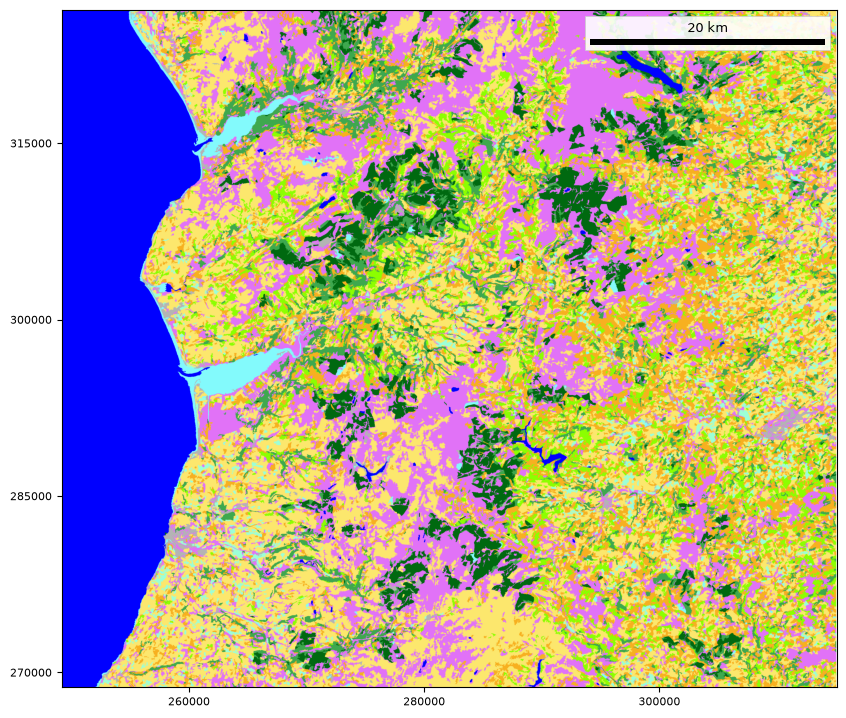

In [18]:
# Create the matplotlib figure
fig, ax = plt.subplots(figsize=(10, 10))

_ = create_thematic_raster_map(ax, out_cls_img)

## 13.1 Visualise subsets

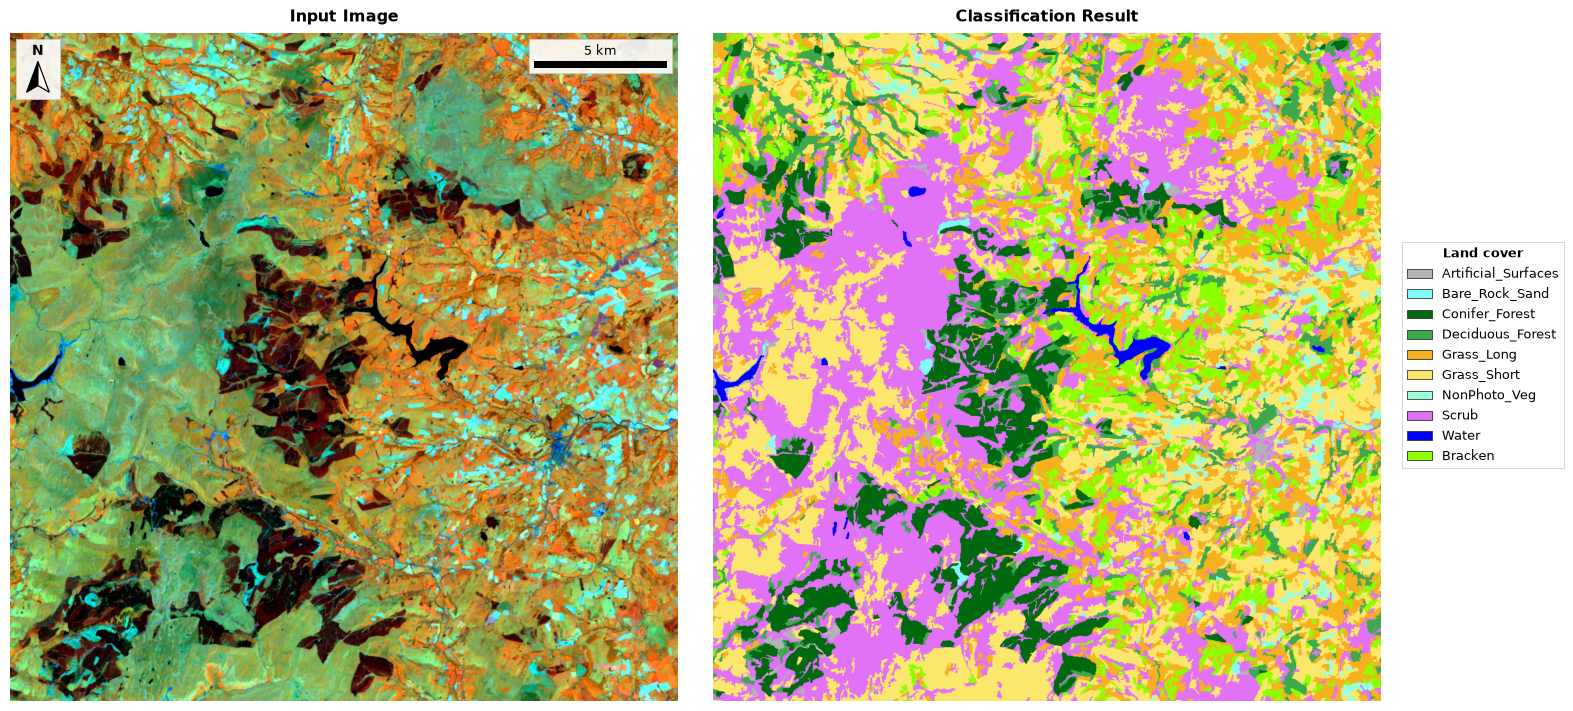

In [19]:
# Define a bbox for the subset to be displayed
sub_img_bbox = [275000, 300000, 275000, 300000]

fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel("rgb", input_img, bands=[8, 9, 3], title="Input Image"),
        map_layout.MapPanel("thematic", out_cls_img, title="Classification Result"),
    ],
    bbox=sub_img_bbox,
    classes_info=cls_cfg,
    legend_title="Land cover",
    figsize=(14, 7),
)

How does this result compare to the one produced by classifying just the image pixels? If you have run notebook 3, its classification is in the same `outputs` directory, so the two can be plotted side by side, sharing one legend:

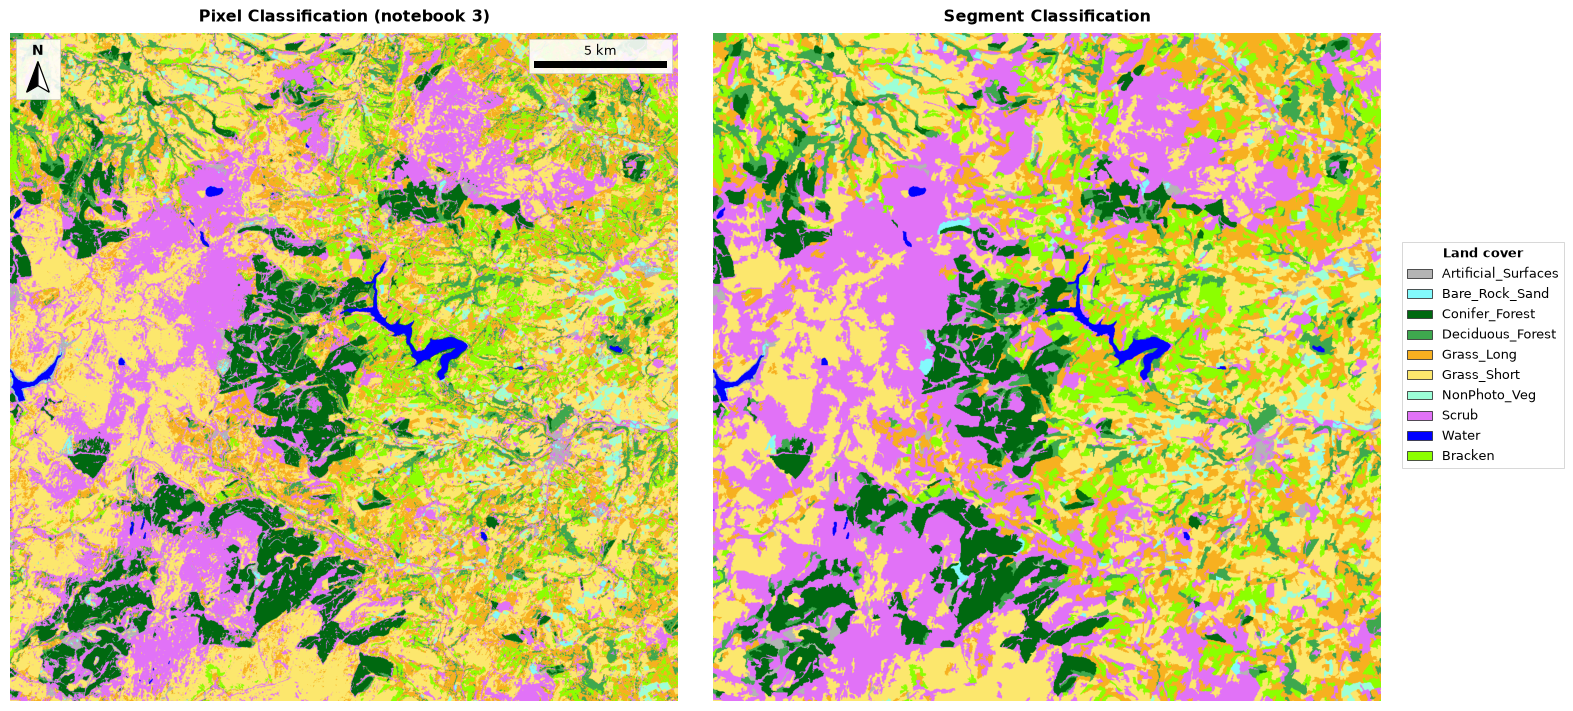

In [20]:
pxl_cls_img = os.path.join(out_dir, "sen2_20180629_t30uvd_orb037_osgb_stdsref_20m_cls.tif")

if os.path.exists(pxl_cls_img):
    fig, axs = map_layout.create_map_panels(
        [
            map_layout.MapPanel("thematic", pxl_cls_img, title="Pixel Classification (notebook 3)"),
            map_layout.MapPanel("thematic", out_cls_img, title="Segment Classification"),
        ],
        bbox=sub_img_bbox,
        classes_info=cls_cfg,
        legend_title="Land cover",
        figsize=(14, 7),
    )
else:
    print("Run 03_supervised_pixel_classification first to compare.")

## Exercise

Only the mean reflectance was used here, so that the pixel samples could be added to the few segment samples. Try adding `"stddev"` to `stats` and some shape metrics (e.g., `shape_metrics=["area", "compactness"]`) in section 6.2. You can then only use the segment samples (section 7.1), so to get enough samples per class you would need training polygons which cover whole segments (or points, one per segment). What would you change in the training data?